# 3 · The cyber beta factor

Shared vulnerabilities as common-cause events, the combined beta factor, and the exact gain of
diversifying. See [Lesson 3](../docs/lessons/03-the-cyber-beta-factor.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cyberccf import plotting
from cyberccf.independence_baseline import MISSION_HOURS, navigation_model, unreliability

plotting.use_style()

In [2]:
from cyberccf.cyber_ccf_model import combined_beta, common_cause_share, cyber_beta, cyber_ccf_model

model = cyber_ccf_model(mission_computers=2)
b_c = cyber_beta(model, "egi_1")
print(f"cyber beta of an EGI: {b_c:.4f}")
print(f"effective beta: {common_cause_share(model, 'egi_1'):.4f} = 1 - (1 - 0.02)(1 - {b_c:.4f}) = {combined_beta(0.02, b_c):.4f}")
print(f"P(loss): {unreliability(model, MISSION_HOURS):.4e}")

cyber beta of an EGI: 0.0783
effective beta: 0.0968 = 1 - (1 - 0.02)(1 - 0.0783) = 0.0968
P(loss): 4.0978e-04


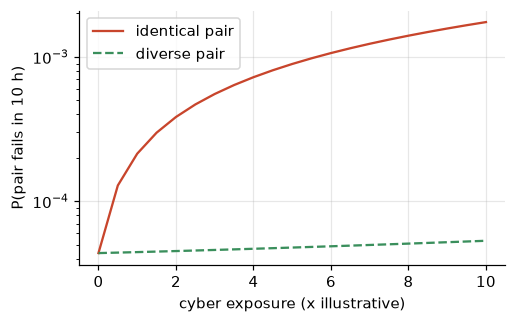

In [3]:
from cyberccf.cyber_ccf_model import diverse_group_unreliability, identical_group_unreliability

scales = np.linspace(0, 10, 21)
lc = 1.7e-5
ident = [identical_group_unreliability(2, 2e-4, 0.02, s * lc, MISSION_HOURS) for s in scales]
div = [diverse_group_unreliability(2, 2e-4, 0.02, s * lc, MISSION_HOURS) for s in scales]
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(scales, ident, color=plotting.CYBER_COLOR, label="identical pair")
ax.semilogy(scales, div, "--", color="#3a8f5c", label="diverse pair")
ax.set_xlabel("cyber exposure (x illustrative)")
ax.set_ylabel("P(pair fails in 10 h)")
ax.legend();

In [4]:
from cyberccf.cyber_ccf_model import split_gain

# Splitting a shared event of probability k: the drop is k(1-k)P(not U and not V) >= 0.
rng = np.random.default_rng(0)
k, pu, pv = rng.random(3)
print("drop with independent U, V:", split_gain(k, pu, pv, pu * pv))

drop with independent U, V: 0.1619370033635564
